# 02 — Exploratory data analysis

## Purpose

This notebook describes the prepared 2011–2015 Lending Club cohort before modelling. It examines cohort size, observed charge-off rates over time, missingness, numerical distributions, extreme values, and outcome rates across categories.

## Input and scope

The only dataset required here is `data/processed/pd_cohort_2011_2015_36m.parquet`, produced by Notebook 01. This notebook does not call KaggleHub, reopen the raw gzip, or modify the saved processed file.

The outcome `charged_off` indicates a final recorded `Charged Off` status rather than default within a fixed time horizon. All plots and group rates are **descriptive**. They are not model predictions, causal effects, or calibrated probabilities.

EDA from processed data

Months: 60
Total loans: 603,589
Total charged off: 84,227

First six months:
             loans  charged_off  charged_off_rate
issue_month                                      
2011-01-01     949           95            0.1001
2011-02-01     831           67            0.0806
2011-03-01     837           76            0.0908
2011-04-01     947           90            0.0950
2011-05-01     957          113            0.1181
2011-06-01    1259          130            0.1033

Last six months:
             loans  charged_off  charged_off_rate
issue_month                                      
2015-07-01   30864         4512            0.1462
2015-08-01   23938         3410            0.1425
2015-09-01   18765         2803            0.1494
2015-10-01   33186         4694            0.1414
2015-11-01   25242         3730            0.1478
2015-12-01   30241         4714            0.1559


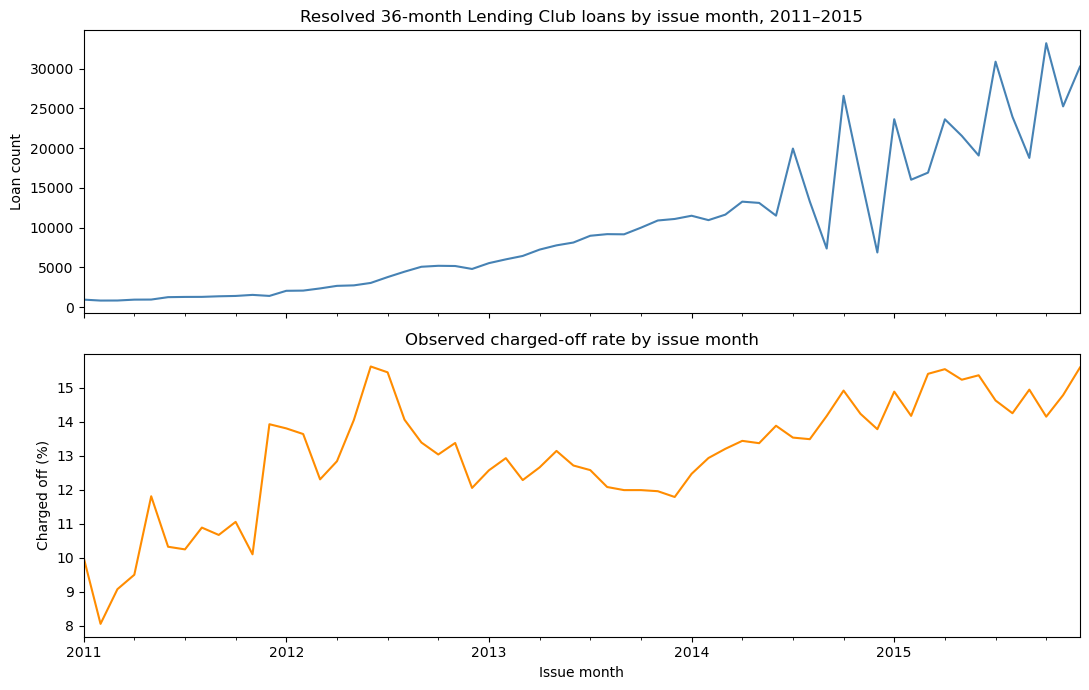

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd().resolve().parent
pd_file = (
    project_root
    / "data"
    / "processed"
    / "pd_cohort_2011_2015_36m.parquet"
)

eda = pd.read_parquet(
    pd_file,
    columns=["issue_month", "charged_off"],
)

monthly_eda = (
    eda.groupby("issue_month")
    .agg(
        loans=("charged_off", "size"),
        charged_off=("charged_off", "sum"),
        charged_off_rate=("charged_off", "mean"),
    )
    .sort_index()
)

print("Months:", len(monthly_eda))
print("Total loans:", f"{monthly_eda['loans'].sum():,}")
print("Total charged off:", f"{monthly_eda['charged_off'].sum():,}")
print("\nFirst six months:")
print(monthly_eda.head(6).round(4).to_string())
print("\nLast six months:")
print(monthly_eda.tail(6).round(4).to_string())

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

monthly_eda["loans"].plot(ax=axes[0], color="steelblue")
axes[0].set_ylabel("Loan count")
axes[0].set_title(
    "Resolved 36-month Lending Club loans by issue month, 2011–2015"
)

(monthly_eda["charged_off_rate"] * 100).plot(
    ax=axes[1], color="darkorange"
)
axes[1].set_ylabel("Charged off (%)")
axes[1].set_xlabel("Issue month")
axes[1].set_title("Observed charged-off rate by issue month")

plt.tight_layout()
plt.show()

In [5]:
fig.savefig(
    project_root / "reports" / "figures" / "monthly_loan_volume_and_observed_charged_off_rate.png",
    dpi=300,
    bbox_inches="tight",
)

distributions and missingness

Shape: (603589, 20)

Missing values:
emp_length    35885
revol_util      307
dti               2

Numerical summary:
                    count      min        1%       50%        99%         max
loan_amnt        603589.0  1000.00   1500.00  10000.00   35000.00    35000.00
int_rate         603589.0     5.32      5.32     11.99      22.15       28.99
annual_inc       603589.0     0.00  17400.00  60000.00  250000.00  9000000.00
dti              603587.0     0.00      1.99     17.16      37.15      999.00
fico_range_low   603589.0   660.00    660.00    685.00     795.00      845.00
fico_range_high  603589.0   664.00    664.00    689.00     799.00      850.00
delinq_2yrs      603589.0     0.00      0.00      0.00       4.00       30.00
inq_last_6mths   603589.0     0.00      0.00      0.00       4.00        8.00
open_acc         603589.0     0.00      3.00     10.00      28.00       84.00
pub_rec          603589.0     0.00      0.00      0.00       2.00       86.00
revol_bal        603589.0

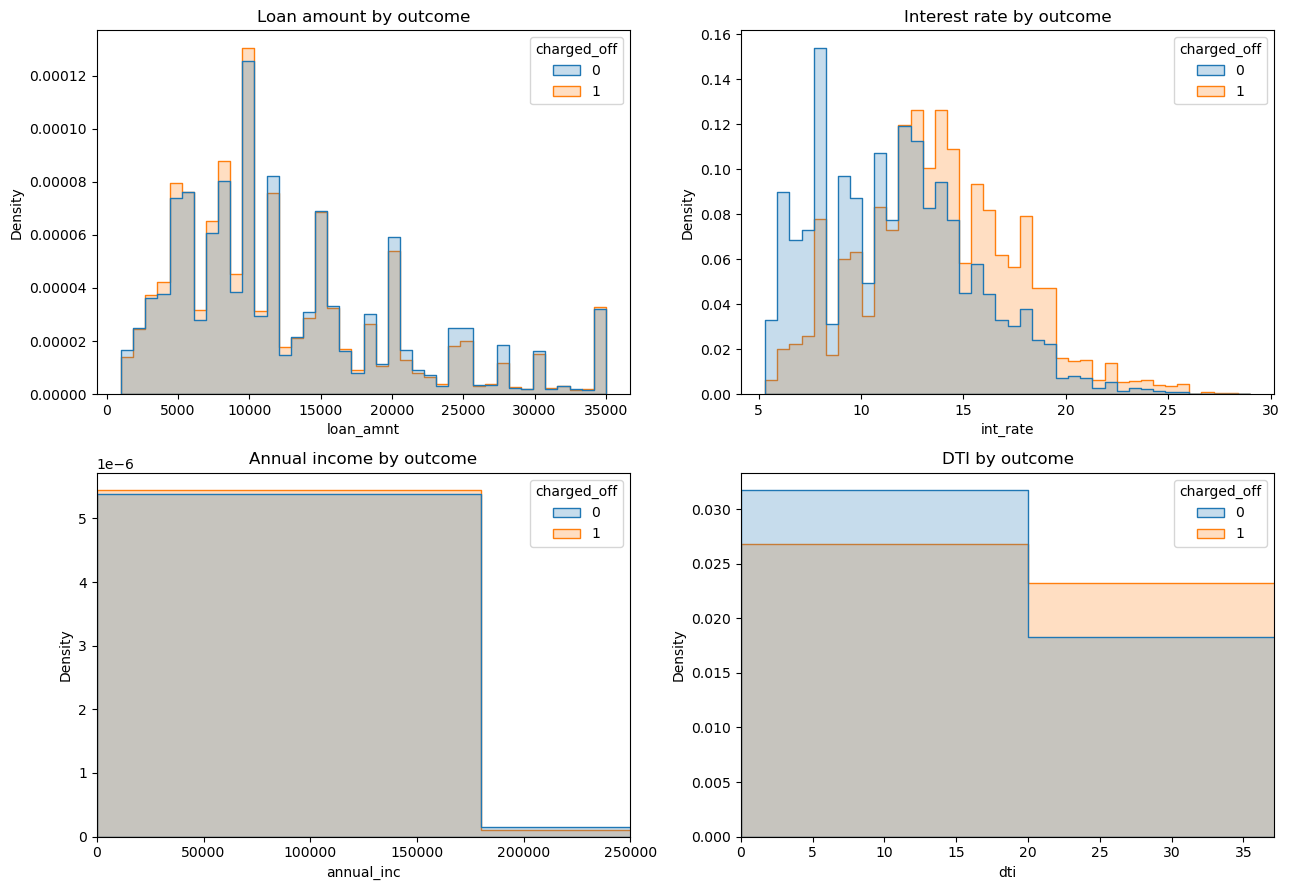

In [6]:
import seaborn as sns

project_root = Path.cwd().resolve().parent
pd_file = (
    project_root
    / "data"
    / "processed"
    / "pd_cohort_2011_2015_36m.parquet"
)

eda_cols = [
    "issue_month", "charged_off",
    "loan_amnt", "int_rate", "annual_inc", "dti",
    "fico_range_low", "fico_range_high",
    "delinq_2yrs", "inq_last_6mths", "open_acc",
    "pub_rec", "revol_bal", "revol_util", "total_acc",
    "grade", "home_ownership", "verification_status",
    "purpose", "emp_length",
]

eda_features = pd.read_parquet(pd_file, columns=eda_cols)

print("Shape:", eda_features.shape)

print("\nMissing values:")
print(
    eda_features.isna()
    .sum()
    .loc[lambda s: s.gt(0)]
    .sort_values(ascending=False)
    .to_string()
)

print("\nNumerical summary:")
numeric_eda_cols = [
    "loan_amnt", "int_rate", "annual_inc", "dti",
    "fico_range_low", "fico_range_high",
    "delinq_2yrs", "inq_last_6mths", "open_acc",
    "pub_rec", "revol_bal", "revol_util", "total_acc",
]
print(
    eda_features[numeric_eda_cols]
    .describe(percentiles=[0.01, 0.50, 0.99])
    .T[["count", "min", "1%", "50%", "99%", "max"]]
    .round(2)
    .to_string()
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(
    data=eda_features,
    x="loan_amnt",
    hue="charged_off",
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0, 0],
)
axes[0, 0].set_title("Loan amount by outcome")

sns.histplot(
    data=eda_features,
    x="int_rate",
    hue="charged_off",
    bins=40,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0, 1],
)
axes[0, 1].set_title("Interest rate by outcome")

sns.histplot(
    data=eda_features,
    x="annual_inc",
    hue="charged_off",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[1, 0],
)
axes[1, 0].set_title("Annual income by outcome")
axes[1, 0].set_xlim(0, eda_features["annual_inc"].quantile(0.99))

sns.histplot(
    data=eda_features,
    x="dti",
    hue="charged_off",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[1, 1],
)
axes[1, 1].set_title("DTI by outcome")
axes[1, 1].set_xlim(0, eda_features["dti"].quantile(0.99))

plt.tight_layout()
plt.show()

In [7]:
fig.savefig(
    project_root / "reports" / "figures" / "histplot01.png",
    dpi=300,
    bbox_inches="tight",
)

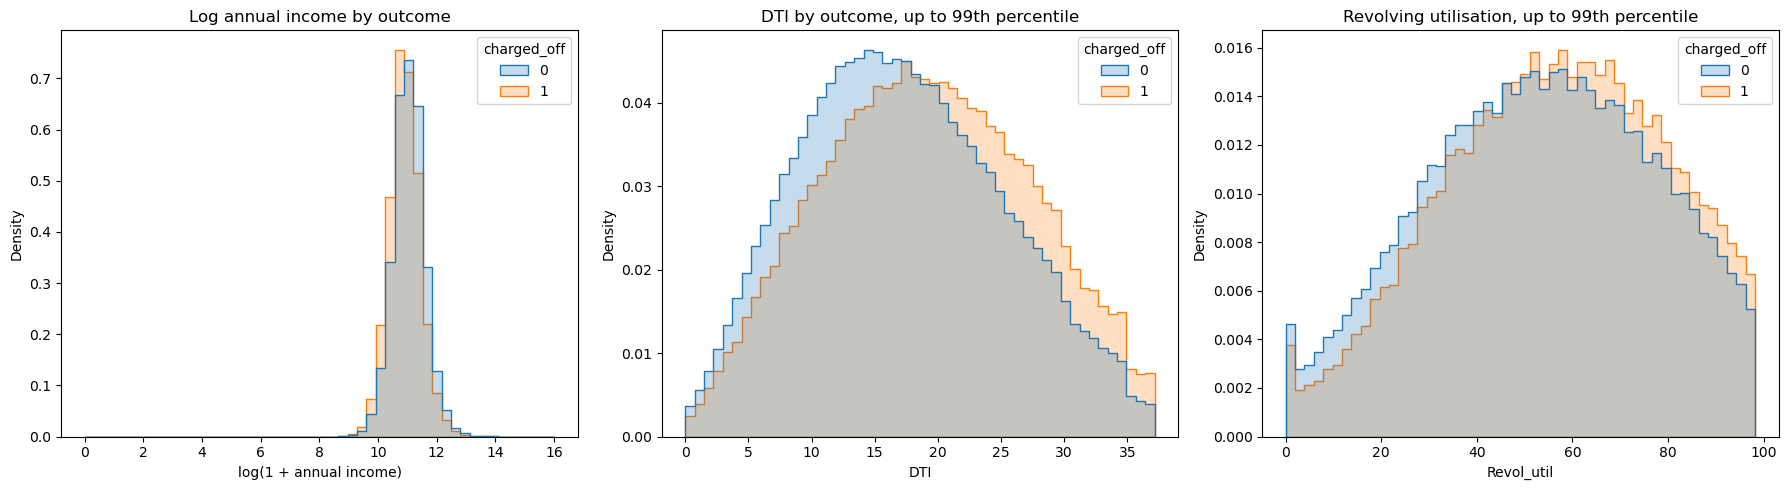

In [8]:
import numpy as np

plot_data = eda_features.copy()

plot_data["annual_inc_log"] = np.log1p(
    plot_data["annual_inc"].clip(lower=0)
)
plot_data["dti_display"] = plot_data["dti"].where(
    plot_data["dti"].le(plot_data["dti"].quantile(0.99))
)
plot_data["revol_util_display"] = plot_data["revol_util"].where(
    plot_data["revol_util"].le(plot_data["revol_util"].quantile(0.99))
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    data=plot_data,
    x="annual_inc_log",
    hue="charged_off",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0],
)
axes[0].set_title("Log annual income by outcome")
axes[0].set_xlabel("log(1 + annual income)")

sns.histplot(
    data=plot_data,
    x="dti_display",
    hue="charged_off",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[1],
)
axes[1].set_title("DTI by outcome, up to 99th percentile")
axes[1].set_xlabel("DTI")

sns.histplot(
    data=plot_data,
    x="revol_util_display",
    hue="charged_off",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[2],
)
axes[2].set_title("Revolving utilisation, up to 99th percentile")
axes[2].set_xlabel("Revol_util")

plt.tight_layout()
plt.show()

In [9]:
fig.savefig(
    project_root / "reports" / "figures" / "histplot02.png",
    dpi=300,
    bbox_inches="tight",
)

category-level outcome rates

In [10]:
categorical_cols = [
    "grade",
    "home_ownership",
    "verification_status",
    "purpose",
    "emp_length",
]

for col in categorical_cols:
    summary = (
        eda_features.groupby(col, dropna=False)
        .agg(
            loans=("charged_off", "size"),
            charged_off=("charged_off", "sum"),
            charged_off_rate=("charged_off", "mean"),
        )
        .sort_values("charged_off_rate", ascending=False)
    )

    summary["charged_off_rate_pct"] = (
        100 * summary["charged_off_rate"]
    ).round(2)

    print(f"\n{col.upper()}")
    print(
        summary[
            ["loans", "charged_off", "charged_off_rate_pct"]
        ].to_string()
    )


GRADE
        loans  charged_off  charged_off_rate_pct
grade                                           
G         473          190                 40.17
F        4106         1356                 33.02
E       20807         5994                 28.81
D       74075        17387                 23.47
C      158263        28483                 18.00
B      207025        23200                 11.21
A      138840         7617                  5.49

HOME_OWNERSHIP
                 loans  charged_off  charged_off_rate_pct
home_ownership                                           
OTHER               40            7                 17.50
NONE                35            6                 17.14
RENT            260580        42955                 16.48
OWN              61632         9186                 14.90
MORTGAGE        281300        32073                 11.40
ANY                  2            0                  0.00

VERIFICATION_STATUS
                      loans  charged_off  charged_o

categorical summary with minimum group-size flags

In [11]:
categorical_cols = [
    "grade",
    "home_ownership",
    "verification_status",
    "purpose",
    "emp_length",
]

category_summaries = {}

for col in categorical_cols:
    summary = (
        eda_features.groupby(col, dropna=False)
        .agg(
            loans=("charged_off", "size"),
            charged_off=("charged_off", "sum"),
            charged_off_rate=("charged_off", "mean"),
        )
        .reset_index()
    )

    summary["charged_off_rate_pct"] = (
        100 * summary["charged_off_rate"]
    ).round(2)

    summary["small_group"] = summary["loans"] < 500
    summary = summary.sort_values(
        ["small_group", "charged_off_rate"],
        ascending=[True, False],
    )

    category_summaries[col] = summary

    print(f"\n{col.upper()}")
    print(summary.to_string(index=False))


GRADE
grade  loans  charged_off  charged_off_rate  charged_off_rate_pct  small_group
    F   4106         1356          0.330248                 33.02        False
    E  20807         5994          0.288076                 28.81        False
    D  74075        17387          0.234722                 23.47        False
    C 158263        28483          0.179973                 18.00        False
    B 207025        23200          0.112064                 11.21        False
    A 138840         7617          0.054862                  5.49        False
    G    473          190          0.401691                 40.17         True

HOME_OWNERSHIP
home_ownership  loans  charged_off  charged_off_rate  charged_off_rate_pct  small_group
          RENT 260580        42955          0.164844                 16.48        False
           OWN  61632         9186          0.149046                 14.90        False
      MORTGAGE 281300        32073          0.114017                 11.40       

## Conclusion and handoff

The processed dataset contains **603,589** loans over **60 issue months**, with **84,227** recorded charge-offs. Monthly loan volume grows substantially over the study period, and the observed charge-off rate varies over time. For example, the selected December 2015 cohort has 4,714 charge-offs among 30,241 resolved loans, or approximately 15.59%.

The numerical audit found strongly skewed income and balance variables and a small number of extreme DTI and utilisation values. Plot-only log or 99th-percentile views improve readability; they do **not** remove, cap, or rewrite observations in the processed Parquet file. Missing values remain in `emp_length`, `revol_util`, and `dti`.

Categorical EDA shows an observed charge-off gradient across Lending Club grades: 5.49% for grade A versus 40.17% for grade G. Grade G has only 473 observations, however, so its estimate warrants more caution than estimates for large groups. Missing `emp_length` is a substantial group—35,885 loans—with a 20.48% observed charge-off rate. Very small categories such as `educational` (1 loan) or `ANY` home ownership (2 loans) should not be ranked as though their rates were stable.

### Interpretation limits

These are associations within the selected, originated-loan cohort. Differences between years or borrower categories could reflect changes in loan mix, selection, underwriting, or other conditions; the plots do not establish causes. Interest rate and grade partly reflect Lending Club's own pricing and risk assessment, so their strong relationship with outcomes should not be presented as a novel independent discovery. The overlapping histograms show **separately normalised distributions**, not the chance of charge-off at each x-axis value.

EDA used outcomes from all years to describe the dataset. Model selection, learned transformations, threshold choice, and calibration must nevertheless be based on training/validation data—not tuned to the 2015 test outcomes.

**Next:** `03-Feature-Engineering.ipynb` reads the processed PD table and creates chronological training, validation, and test splits before fitting any preprocessing.